# Chapter 10: Dynamic and Sequential Games

This notebook reruns four worked examples from the chapter: a fight threat solved by backward induction, the patience needed for grim-trigger pricing, entry against an incumbent of unknown strength, and the cost of a war of attrition. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def game_tree(ax, nodes, edges, highlight_edges=None, xlabel="Stage", ylabel="Branch"):
    """Small extensive-form tree.

    ``nodes`` maps id -> (x, y, text); ``edges`` is a list of (from, to, action label).
    ``highlight_edges`` is a set of (from, to) drawn thick in teal (the equilibrium path).
    """
    highlight_edges = set(highlight_edges or [])
    for a, b, act in edges:
        (x0, y0, _), (x1, y1, _) = nodes[a], nodes[b]
        hot = (a, b) in highlight_edges
        ax.plot([x0, x1], [y0, y1], color=PALETTE["teal"] if hot else PALETTE["grey"], linewidth=3 if hot else 1.4)
        ax.annotate(act, ((x0 + x1) / 2, (y0 + y1) / 2), ha="center", va="center", fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none"})
    for x, y, text in nodes.values():
        ax.scatter([x], [y], s=40, color=PALETTE["ink"], zorder=4)
        if text:
            ax.annotate(text, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=LABEL_SIZE)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def backward_induction(tree):
    """Solve a finite perfect-information game tree by backward induction.

    A node is (name, player index, {action: child}); a leaf is a tuple of payoffs. Ties are broken
    toward the first listed action and reported in ``ties``.
    Returns {"payoffs", "path" (actions on the equilibrium path), "plan" ({node name: action}), "ties"}.
    Principle: backward-induction. Book (ch010): Stay Out (0, 5); after Enter, Fight (-2, -1) or
    Accommodate (3, 2): the incumbent compares 2 > -1, the entrant 3 > 0, outcome (3, 2).
    """
    plan, ties = {}, []

    def solve(node):
        if not (isinstance(node, tuple) and len(node) == 3 and isinstance(node[2], dict)):
            return tuple(node), []
        name, player, moves = node
        best = None
        for action, child in moves.items():
            pay, path = solve(child)
            if best is None or pay[player] > best[1][player]:
                best = (action, pay, path)
            elif pay[player] == best[1][player]:
                ties.append(name)
        plan[name] = best[0]
        return best[1], [best[0]] + best[2]

    payoffs, path = solve(tree)
    return {"payoffs": payoffs, "path": path, "plan": plan, "ties": ties}


def grim_trigger_threshold(R, T, P):
    """Smallest discount factor sustaining grim-trigger cooperation: (T - R) / (T - P).

    Principle: one-shot-deviation-principle. Book (ch010): R = 8, T = 12, P = 5 gives 4/7 = 0.571.
    """
    return (T - R) / (T - P)


def repeated_values(delta, R, T, P, k=None):
    """Value of cooperating forever versus deviating once and then being punished.

    V_C = R / (1 - delta). With k=None (grim trigger) V_D = T + delta P / (1 - delta); with a finite
    punishment of k periods V_D = T + P (delta + ... + delta^k) + delta^(k+1) R / (1 - delta).
    Returns (V_C, V_D). Principle: one-shot-deviation-principle. Book (ch010): delta = 0.7, R = 8,
    T = 12, P = 5 gives 26.667 and 23.667; delta = 0.5 gives 16 and 17.
    """
    vc = R / (1 - delta)
    if k is None:
        vd = T + delta * P / (1 - delta)
    else:
        vd = T + P * sum(delta ** t for t in range(1, k + 1)) + delta ** (k + 1) * R / (1 - delta)
    return vc, vd


def expected_entry_payoff(q, fight=-1.0, acc=3.0):
    """Entrant's expected payoff when a Strong incumbent (prob q) fights and a Weak one accommodates.

    Principle: sequential-equilibrium. Book (ch010): 0.30(-1) + 0.70(3) = 1.80; 0.80(-1) + 0.20(3) = -0.20.
    """
    return q * fight + (1 - q) * acc


def war_of_attrition(V, c, deadline=None):
    """Symmetric war of attrition with exponential concession.

    Hazard h = c / V; mean concession 1/h; expected duration 1/(2h); one-week latent-clock
    probability 1 - e^(-h); either-clock probability 1 - e^(-2h); expected combined cost
    2c / (2h) = V; with a deadline, combined cost is at most 2 c deadline.
    Principle: war-of-attrition-game. Book (ch010): V = 120, c = 3 gives 0.025, 40, 20, 0.02469,
    0.04877, 120 and a 10-week bound of 60.
    """
    h = c / V
    out = {"h": h, "mean_concession": 1 / h, "duration": 1 / (2 * h), "p_week": 1 - math.exp(-h),
           "p_either_week": 1 - math.exp(-2 * h), "expected_cost": 2 * c / (2 * h)}
    if deadline is not None:
        out["cost_bound"] = 2 * c * deadline
    return out


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(backward_induction=backward_induction, grim_trigger_threshold=grim_trigger_threshold, repeated_values=repeated_values, expected_entry_payoff=expected_entry_payoff, war_of_attrition=war_of_attrition)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'backward-induction': {'stay_out': (0, 5),
                        'fight': (-2, -1),
                        'accommodate': (3, 2),
                        'outcome': (3, 2),
                        'acc_exclusive': -3,
                        'outcome_exclusive': (0, 5)},
 'one-shot-deviation-principle': {'R': 8,
                                  'T': 12,
                                  'S': 2,
                                  'P': 5,
                                  'delta': 0.7,
                                  'V_C': 26.667,
                                  'V_D': 23.667,
                                  'margin': 3,
                                  'punish_obey': 16.667,
                                  'punish_deviate': 13.667,
                                  'threshold': 0.5714285714285714,
                                  'delta_low': 0.5,
                                  'V_C_low': 16,
                                  'V_D_low': 17},
 'sequential-equilibrium': {'q': 0.3,
                            'fight': -1,
                            'acc': 3,
                            'ev': 1.8,
                            'q_alt': 0.8,
                            'ev_alt': -0.2},
 'war-of-attrition-game': {'V': 120,
                           'c': 3,
                           'h': 0.025,
                           'mean': 40,
                           'duration': 20,
                           'p_week': 0.02469,
                           'p_either': 0.04877,
                           'cost': 120,
                           'deadline': 10,
                           'bound': 60},
 'constructed': {'backward-induction': {'acc': [0], 'fight': [1]},
                 'one-shot-deviation-principle': {'delta': [0.6, 0.9], 'T': [10, 14]},
                 'sequential-equilibrium': {'q': [0.5, 0.75]},
                 'war-of-attrition-game': {'V': [60, 240], 'c': [6]}}}


def entry_picture(acc=2, fight=-1):
    tree = ("entrant", 0, {"Enter": ("incumbent", 1, {"Fight": (-2, fight), "Accommodate": (3, acc)}),
                           "Stay out": (0, 5)})
    res = games.backward_induction(tree)
    inc = res["plan"]["incumbent"]
    ent = res["plan"]["entrant"]
    nodes = {"E": (0, 0, "Entrant"), "I": (1, 0.6, "Incumbent"), "S": (1, -0.8, "(0, 5)"),
             "F": (2, 1.1, f"(-2, {fight})"), "A": (2, 0.1, f"(3, {acc})")}
    edges = [("E", "I", "Enter"), ("E", "S", "Stay out"), ("I", "F", "Fight"), ("I", "A", "Accommodate")]
    hot = {("I", "F") if inc == "Fight" else ("I", "A")}
    hot.add(("E", "I") if ent == "Enter" else ("E", "S"))
    fig, ax = new_figure()
    game_tree(ax, nodes, edges, highlight_edges=hot, xlabel="Stage (entrant moves first)",
              ylabel="Branch; payoffs are (entrant, incumbent)")
    ax.set_xlim(-0.2, 2.6)
    ax.set_ylim(-1.2, 1.5)
    inc_val = fight if inc == "Fight" else acc
    other = acc if inc == "Fight" else fight
    ent_after = -2 if inc == "Fight" else 3
    tie = "incumbent" in res["ties"]
    first = (f"After entry the incumbent compares Accommodate {acc} with Fight {fight}: "
             + ("they tie, and the tie is broken toward Fight. " if tie else
                f"{max(acc, fight)} > {min(acc, fight)}, so it chooses {inc}. "))
    second = (f"The entrant compares {ent_after} from Enter with 0 from Stay out and chooses "
              f"{'Enter' if ent == 'Enter' else 'Stay out'}.")
    metrics = {"Incumbent after entry": inc, "Entrant": ent, "Payoffs (entrant, incumbent)":
               f"({res['payoffs'][0]}, {res['payoffs'][1]})",
               "Fight threat credible": "yes" if inc == "Fight" else "no"}
    interp = (first + second + f" The outcome pays ({res['payoffs'][0]}, {res['payoffs'][1]}); the incumbent's gain "
              f"from its choice after entry is {inc_val} - ({other}) = {inc_val - other}.")
    steps = [f"Incumbent: Accommodate {acc} vs Fight {fight}: {inc}",
             f"Entrant: Enter {ent_after} vs Stay out 0: {ent}",
             f"Outcome ({res['payoffs'][0]}, {res['payoffs'][1]})"]
    alt = (f"Entry game tree; the incumbent's best reply is {inc} and the entrant's choice is {ent}, giving "
           f"({res['payoffs'][0]}, {res['payoffs'][1]}).")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def patience_picture(delta=0.7, temp=12):
    vc, vd = games.repeated_values(delta, 8, temp, 5)
    thr = games.grim_trigger_threshold(8, temp, 5)
    ds = np.linspace(0.3, 0.95, 200)
    fig, ax = new_figure()
    ax.plot(ds, 8 / (1 - ds), color=PALETTE["teal"], linewidth=2.2, label="cooperate: 8 / (1 - delta)")
    ax.plot(ds, temp + 5 * ds / (1 - ds), color=PALETTE["terracotta"], linewidth=2.2,
            label=f"deviate: {temp} + 5 delta / (1 - delta)")
    vline(ax, thr, f"threshold {num(thr, 3)}", col="grey", y_frac=0.95, ha="left")
    mark(ax, delta, vc, col="teal")
    mark(ax, delta, vd, col="terracotta")
    ax.set_xlim(0.3, 0.95)
    ax.set_ylim(0, 170)
    ax.legend(loc="upper left", frameon=False, bbox_to_anchor=(0, 0.88))
    ax.set_xlabel("Discount factor delta")
    ax.set_ylabel("Present value")
    margin = vc - vd
    verdict = ("cooperation holds" if margin > 1e-9 else "the firm is indifferent" if abs(margin) <= 1e-9
               else "deviation pays, so grim trigger fails")
    tail = 5 * delta / (1 - delta)
    metrics = {"V_C": num(vc, 3), "V_D": num(vd, 3), "Margin V_C - V_D": num(margin, 3),
               "Threshold delta": num(thr, 3), "Cooperation sustained": "yes" if margin >= -1e-9 else "no"}
    interp = (f"V_C = 8 / (1 - {delta}) = {num(vc, 3)}. V_D = {temp} + {delta} x 5 / (1 - {delta}) = {temp} + "
              f"{num(tail, 3)} = {num(vd, 3)}. The margin is {num(margin, 3)}, so {verdict}. Cooperation needs delta "
              f"of at least ({temp} - 8) / ({temp} - 5) = {num(thr, 3)}. In the punishment state Low earns 5 and High "
              f"earns 2 against Low with the same future, so no one-shot deviation pays there.")
    steps = [f"V_C = 8 / {num(1 - delta, 1)} = {num(vc, 3)}", f"V_D = {temp} + {num(tail, 3)} = {num(vd, 3)}",
             f"Margin = {num(vc, 3)} - {num(vd, 3)} = {num(margin, 3)}",
             f"Threshold = {temp - 8} / {temp - 5} = {num(thr, 3)}"]
    alt = (f"Cooperation and deviation values against delta crossing at {num(thr, 3)}; at {delta} they are "
           f"{num(vc, 3)} and {num(vd, 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def seq_picture(q=0.3):
    ev = games.expected_entry_payoff(q, -1, 3)
    qs = np.linspace(0, 1, 101)
    fig, ax = new_figure()
    ax.plot(qs, 3 - 4 * qs, color=PALETTE["navy"], linewidth=2.2, label="Enter: q(-1) + (1 - q)3 = 3 - 4q")
    hline(ax, 0, "Out: 0", col="grey", x_frac=0.02)
    vline(ax, 0.75, "break-even q = 0.75", col="grey", y_frac=0.12, ha="right")
    mark(ax, q, ev, f"q = {q}: {num(ev, 2)}", col="teal" if ev > 0 else "terracotta", dx=8, dy=6)
    ax.set_xlim(0, 1)
    ax.set_ylim(-1.3, 3.3)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Prior probability q that the incumbent is Strong")
    ax.set_ylabel("Entrant's expected payoff")
    dec = "Enter" if ev > 1e-12 else ("indifferent between Enter and Out" if abs(ev) <= 1e-12 else "Out")
    metrics = {"Expected payoff of Enter": num(ev, 2), "Entrant's choice": dec,
               "Strong incumbent": "fights (2 > 1)", "Weak incumbent": "accommodates (1 > -2)"}
    interp = (f"Strong fights because 2 > 1 and Weak accommodates because 1 > -2, whatever the prior. Entry pays "
              f"{q} x (-1) + {num(1 - q, 2)} x 3 = {num(-q, 2)} + {num(3 * (1 - q), 2)} = {num(ev, 2)} against 0 for "
              f"Out, so the entrant's choice is: {dec}.")
    steps = [f"{q} x (-1) = {num(-q, 2)}", f"{num(1 - q, 2)} x 3 = {num(3 * (1 - q), 2)}",
             f"E[Enter] = {num(-q, 2)} + {num(3 * (1 - q), 2)} = {num(ev, 2)}", f"Choice: {dec}"]
    alt = f"Entry payoff line 3 - 4q crossing zero at 0.75; at q = {q} it is {num(ev, 2)}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def attrition_picture(prize=120, c=3):
    r = games.war_of_attrition(prize, c, deadline=10)
    h = r["h"]
    ts = np.linspace(0, 80, 300)
    fig, ax = new_figure()
    ax.plot(ts, np.exp(-2 * h * ts), color=PALETTE["navy"], linewidth=2.2, label="P(contest still running)")
    vline(ax, r["duration"], f"expected duration {num(r['duration'], 0)} weeks", col="teal", y_frac=0.95)
    vline(ax, 10, "10-week deadline", col="grey", y_frac=0.12, style="dotted")
    ax.set_xlim(0, 80)
    ax.set_ylim(0, 1.05)
    ax.legend(loc="upper right", frameon=False, bbox_to_anchor=(1, 0.85))
    ax.set_xlabel("Weeks")
    ax.set_ylabel("Probability")
    metrics = {"Hazard h": num(h, 4), "Mean concession time": f"{num(r['mean_concession'], 0)} weeks",
               "Expected duration": f"{num(r['duration'], 0)} weeks",
               "One-week clock probability": pct(r["p_week"], 2),
               "Expected combined cost": num(r["expected_cost"], 0), "Cost bound with deadline": num(r["cost_bound"], 0)}
    interp = (f"h = {c} / {prize} = {num(h, 4)} per week, so each vendor's mean concession time is 1 / h = "
              f"{num(r['mean_concession'], 0)} weeks and the contest lasts 1 / (2h) = {num(r['duration'], 0)} weeks on "
              f"average. One vendor's clock rings within a week with probability 1 - e^(-{num(h, 4)}) = "
              f"{num(r['p_week'], 5)}. Expected combined cost is 2 x {c} x {num(r['duration'], 0)} = "
              f"{num(r['expected_cost'], 0)}, the whole prize. A 10-week deadline caps it at 2 x {c} x 10 = "
              f"{num(r['cost_bound'], 0)}.")
    steps = [f"h = {c} / {prize} = {num(h, 4)}", f"Duration = 1 / (2 x {num(h, 4)}) = {num(r['duration'], 0)} weeks",
             f"One-week probability = 1 - e^(-{num(h, 4)}) = {num(r['p_week'], 5)}",
             f"Cost = 2 x {c} x {num(r['duration'], 0)} = {num(r['expected_cost'], 0)}",
             f"Deadline bound = 2 x {c} x 10 = {num(r['cost_bound'], 0)}"]
    alt = f"Survival curve of the contest with hazard {num(2 * h, 4)}; expected duration {num(r['duration'], 0)} weeks."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Backward induction: is the fight threat credible?

Stay out gives (0, 5); after entry Fight gives (-2, -1) and Accommodate (3, 2). The incumbent compares $2>-1$ and the entrant $3>0$.

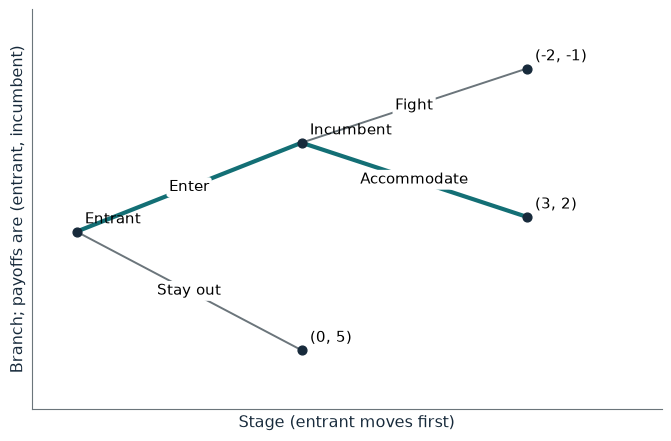

Incumbent after entry         Accommodate
Entrant                       Enter
Payoffs (entrant, incumbent)  (3, 2)
Fight threat credible         no

Worked steps:
  1. Incumbent: Accommodate 2 vs Fight -1: Accommodate
  2. Entrant: Enter 3 vs Stay out 0: Enter
  3. Outcome (3, 2)

After entry the incumbent compares Accommodate 2 with Fight -1: 2 > -1, so it chooses Accommodate. The entrant compares 3 from Enter with 0 from Stay out and chooses Enter. The outcome pays (3, 2); the incumbent's gain from its choice after entry is 2 - (-1) = 3.


In [2]:
show(entry_picture(acc=2, fight=-1))

Change one input, `acc`, and hold the others at the book's values:

In [3]:
sweep(entry_picture, 'acc', [2, 0, -3], {'fight': -1}, ['Incumbent after entry', 'Entrant', 'Payoffs (entrant, incumbent)'])

acc | Incumbent after entry | Entrant | Payoffs (entrant, incumbent)
2 | Accommodate | Enter | (3, 2)
0 | Accommodate | Enter | (3, 0)
-3 | Fight | Stay out | (0, 5)


The threat is empty while accommodating pays the incumbent more than fighting. With exclusivity (Accommodate -3) it fights, and the entrant stays out.

## 2. One-shot deviation principle: grim-trigger pricing

$$V_C=\frac{8}{1-0.7}=26.667, \qquad V_D=12+0.7\frac{5}{1-0.7}=23.667$$

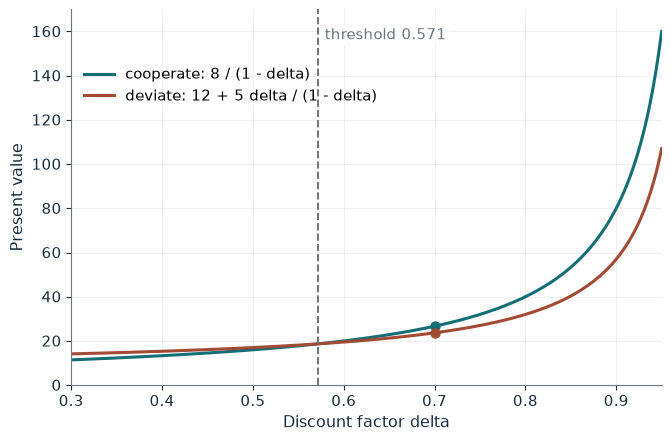

V_C                    26.667
V_D                    23.667
Margin V_C - V_D       3.000
Threshold delta        0.571
Cooperation sustained  yes

Worked steps:
  1. V_C = 8 / 0.3 = 26.667
  2. V_D = 12 + 11.667 = 23.667
  3. Margin = 26.667 - 23.667 = 3.000
  4. Threshold = 4 / 7 = 0.571

V_C = 8 / (1 - 0.7) = 26.667. V_D = 12 + 0.7 x 5 / (1 - 0.7) = 12 + 11.667 = 23.667. The margin is 3.000, so cooperation holds. Cooperation needs delta of at least (12 - 8) / (12 - 5) = 0.571. In the punishment state Low earns 5 and High earns 2 against Low with the same future, so no one-shot deviation pays there.


In [4]:
show(patience_picture(delta=0.7, temp=12))

Change one input, `delta`, and hold the others at the book's values:

In [5]:
sweep(patience_picture, 'delta', [0.5, 0.6, 0.7, 0.9], {'temp': 12}, ['V_C', 'V_D', 'Cooperation sustained'])

delta | V_C | V_D | Cooperation sustained
0.5 | 16.000 | 17.000 | no
0.6 | 20.000 | 19.500 | yes
0.7 | 26.667 | 23.667 | yes
0.9 | 80.000 | 57.000 | yes


Cooperation holds for delta of at least 4/7 = 0.571; at 0.5, deviation pays 17 against 16.

## 3. Sequential equilibrium: entry against an unknown incumbent

$$0.30(-1)+0.70(3)=-0.30+2.10=1.80>0, \qquad 0.80(-1)+0.20(3)=-0.20<0$$

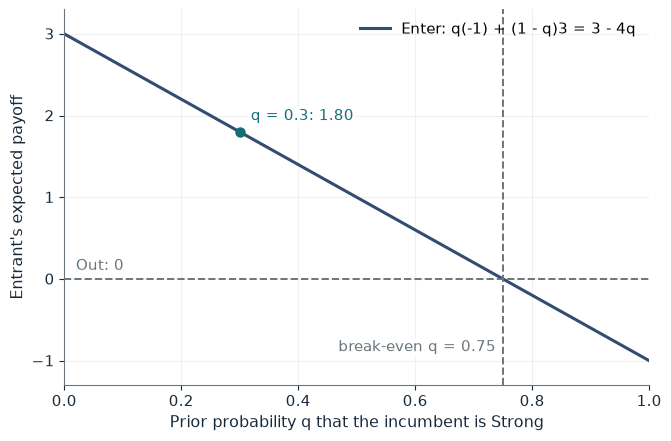

Expected payoff of Enter  1.80
Entrant's choice          Enter
Strong incumbent          fights (2 > 1)
Weak incumbent            accommodates (1 > -2)

Worked steps:
  1. 0.3 x (-1) = -0.30
  2. 0.70 x 3 = 2.10
  3. E[Enter] = -0.30 + 2.10 = 1.80
  4. Choice: Enter

Strong fights because 2 > 1 and Weak accommodates because 1 > -2, whatever the prior. Entry pays 0.3 x (-1) + 0.70 x 3 = -0.30 + 2.10 = 1.80 against 0 for Out, so the entrant's choice is: Enter.


In [6]:
show(seq_picture(q=0.3))

Change one input, `q`, and hold the others at the book's values:

In [7]:
sweep(seq_picture, 'q', [0.3, 0.5, 0.75, 0.8], {}, ['Expected payoff of Enter', "Entrant's choice"])

q | Expected payoff of Enter | Entrant's choice
0.3 | 1.80 | Enter
0.5 | 1.00 | Enter
0.75 | 0.00 | indifferent between Enter and Out
0.8 | -0.20 | Out


Entry pays while q is below 0.75; at exactly 0.75 the entrant is indifferent.

## 4. War of attrition: a standards contest

$$h=\frac{c}{V}=\frac{3}{120}=0.025, \qquad \frac{1}{2h}=\frac{1}{0.05}=20\text{ weeks}$$

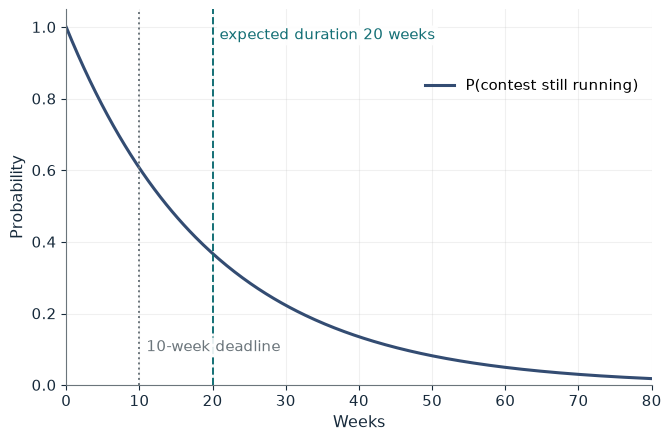

Hazard h                    0.0250
Mean concession time        40 weeks
Expected duration           20 weeks
One-week clock probability  2.47%
Expected combined cost      120
Cost bound with deadline    60

Worked steps:
  1. h = 3 / 120 = 0.0250
  2. Duration = 1 / (2 x 0.0250) = 20 weeks
  3. One-week probability = 1 - e^(-0.0250) = 0.02469
  4. Cost = 2 x 3 x 20 = 120
  5. Deadline bound = 2 x 3 x 10 = 60

h = 3 / 120 = 0.0250 per week, so each vendor's mean concession time is 1 / h = 40 weeks and the contest lasts 1 / (2h) = 20 weeks on average. One vendor's clock rings within a week with probability 1 - e^(-0.0250) = 0.02469. Expected combined cost is 2 x 3 x 20 = 120, the whole prize. A 10-week deadline caps it at 2 x 3 x 10 = 60.


In [8]:
show(attrition_picture(prize=120, c=3))

Change one input, `prize`, and hold the others at the book's values:

In [9]:
sweep(attrition_picture, 'prize', [60, 120, 240], {'c': 3}, ['Hazard h', 'Expected duration', 'Expected combined cost'])

prize | Hazard h | Expected duration | Expected combined cost
60 | 0.0500 | 10 weeks | 60
120 | 0.0250 | 20 weeks | 120
240 | 0.0125 | 40 weeks | 240


The contest lasts 20 weeks on average and burns 120, the whole prize. A 10-week deadline caps combined spending at 60.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

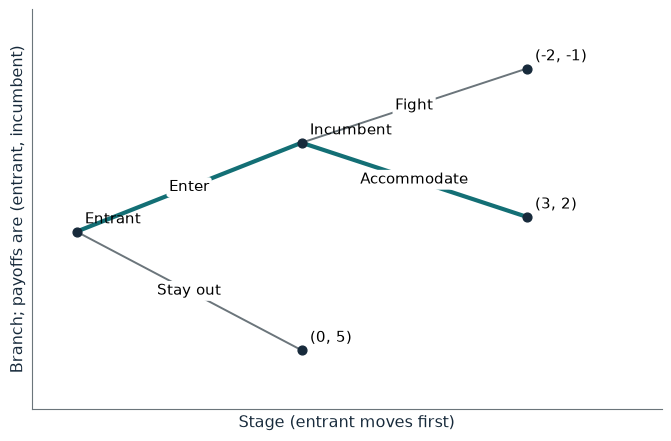

Incumbent after entry         Accommodate
Entrant                       Enter
Payoffs (entrant, incumbent)  (3, 2)
Fight threat credible         no

Worked steps:
  1. Incumbent: Accommodate 2 vs Fight -1: Accommodate
  2. Entrant: Enter 3 vs Stay out 0: Enter
  3. Outcome (3, 2)

After entry the incumbent compares Accommodate 2 with Fight -1: 2 > -1, so it chooses Accommodate. The entrant compares 3 from Enter with 0 from Stay out and chooses Enter. The outcome pays (3, 2); the incumbent's gain from its choice after entry is 2 - (-1) = 3.


In [10]:
show(entry_picture(acc=2, fight=-1))

## Practice

**1.** With Accommodate at 0 and Fight at 1, what is the outcome?

<details><summary>Answer</summary>

The incumbent fights (1 > 0), so the entrant stays out: (0, 5).

</details>

**2.** With a deviation payoff of 14, what is the threshold delta?

<details><summary>Answer</summary>

(14 - 8) / (14 - 5) = 6/9 = 0.667.

</details>

**3.** With V = 240 and c = 3, what are h and the expected duration?

<details><summary>Answer</summary>

h = 0.0125; duration 1 / (2h) = 40 weeks.

</details>